In [1]:
import pandas as pd
import os
import sys
import json

import seaborn as sns
import numpy as np
import networkx as nx
from pyvis.network import Network

sys.path.append("../functions/")
import networks

In [2]:
import matplotlib.pyplot as plt

In [3]:
from scipy import stats

In [4]:
%load_ext autoreload
%autoreload 2

In [5]:
with open("../data/Venturelli2018/generated/metid2metname.json") as json_file:
    metid2metname = json.load(json_file)

**Read and process experimental relative abundances**

In [6]:
abundances_exp_list = []

for file in os.listdir("../data/Venturelli2018/generated/communities_steadiercom/"):
    if file.endswith(".tsv"):
        abundance = pd.read_csv("../data/Venturelli2018/generated/communities_steadiercom/"+file,sep="\t",header=None)
        abundances_exp_list.append(abundance)
        
abundances_exp = pd.concat(abundances_exp_list)
abundances_exp.columns = ["community","member","abundance"]

abundances_exp = abundances_exp.set_index(["community","member"])["abundance"]
abundances_exp = abundances_exp.unstack().T

**Read and process simulated relative abundance**

In [7]:
abundance = {}

for file in os.listdir("../output/Venturelli2018/results_steadiercom/results_growth_test/"):
    if file.endswith(".tsv") and file.endswith("_abundance.tsv"):
        abundance[file[:-4]] = pd.read_csv("../output/Venturelli2018/results_steadiercom/results_growth_test/"+file,sep="\t")

abundance_df = pd.concat(abundance)
abundance_df = abundance_df.reset_index(drop=True)

**Read and process simulation interaction results**

In [16]:

# Identify compounds that are not of interest (part of M9)
media_db = pd.read_csv("https://raw.githubusercontent.com/cdanielmachado/carveme/refs/heads/master/carveme/data/input/media_db.tsv",sep="\t")
compounds = media_db[media_db.medium=="M9"].compound.values
compounds = list(compounds)
compounds.remove("glc__D")
m9_compounds = ["M_"+met+"__91__e__93__" for met in compounds]

# Read and join results
results_raw= {}

for file in os.listdir("../output/Venturelli2018/results_steadiercom/results_growth_test/"):
    if file.endswith(".tsv") and not file.endswith("_abundance.tsv"):
        results_raw[file[:-4]] = pd.read_csv("../output/Venturelli2018/results_steadiercom/results_growth_test/"+file,sep="\t")

results_raw_df = pd.concat(results_raw)
results_raw_df = results_raw_df.reset_index(drop=True)

# Add extra layers and remove uninteresting results
results = results_raw_df.copy()
results["mass_rate*frequency"] = results["frequency"]*results["mass_rate"]
results = results[~results.compound.isin(m9_compounds)] # REMOVED M9 COMPOUNDS

**Adjust results for simualted interactions**

*Original results - many samples are dominated by one species*

In [17]:
tot_samples = {comm:1500 for comm in results.community.unique()}

*Filter out the samples with only ONE dominating species*

In [18]:
abundance_df_reduced = abundance_df.copy()
counts = abundance_df_reduced[["sample","community"]].value_counts()
multiple_entries =counts[counts>1].index #Filtering...
abundance_df_reduced = abundance_df_reduced.set_index(["sample","community"]).loc[multiple_entries].reset_index()

*Filtering cuts away most of the samples*

In [19]:
inter_samples_dict = {}
for comm in abundance_df_reduced.community.unique():
    
    abundance_df_comm= abundance_df_reduced.query(f"community=='{comm}'")

    inter_samples = len(abundance_df_comm["sample"].unique())
    
    inter_samples_dict[comm]=inter_samples

*Frequency is off by*

In [20]:
conversion = {comm:1/(inter_samples/tot_samples[comm]) for comm,inter_samples in inter_samples_dict.items()}
conversion

{'DP-': 4.9504950495049505,
 'NONE': 4.716981132075472,
 'BO-': 4.823151125401929,
 'CH-': 4.823151125401929,
 'FP-': 5.928853754940712,
 'BV-': 4.672897196261682,
 'BH-': 4.901960784313726,
 'BT-': 4.88599348534202,
 'BU-': 4.87012987012987,
 'CA-': 6.0,
 'PC-': 4.9504950495049505,
 'EL-': 5.1194539249146755,
 'ER-': 5.136986301369864}

In [21]:
results_env = results[(results.donor!="environment") & (results.receiver!="environment") ].copy()

results_env.frequency=results_env.apply(lambda x: x.frequency*conversion[x.community],axis=1)
results_env

,donor,receiver,compound,mass_rate,rate,frequency,community,medium,mass_rate*frequency
57,Bacteroides_uniformis_ATCC_8492,Blautia_hydrogenotrophica_DSM_10507,M_fru__91__e__93__,1.460153e-01,8.104961e-01,0.003300,PC-,LB_extend,9.734350e-05
65,Bacteroides_uniformis_ATCC_8492,Clostridium_hiranonis_TO_931_DSM_13275,M_fru__91__e__93__,1.196182e-01,6.639726e-01,0.006601,PC-,LB_extend,1.594910e-04
69,Eubacterium_rectale_ATCC_33656,Desulfovibrio_piger_ATCC_29098,M_lac_L__91__e__93__,1.130827e-01,1.269596e+00,0.009901,PC-,LB_extend,2.261653e-04
74,Faecalibacterium_prausnitzii_A2_165,Bacteroides_vulgatus_ATCC_8482,M_fru__91__e__93__,1.099783e-01,6.104634e-01,0.009901,PC-,LB_extend,2.199566e-04
77,Blautia_hydrogenotrophica_DSM_10507,Desulfovibrio_piger_ATCC_29098,M_lac_D__91__e__93__,1.084407e-01,1.217480e+00,0.009901,PC-,LB_extend,2.168815e-04
...,...,...,...,...,...,...,...,...,...
8546,Clostridium_hiranonis_TO_931_DSM_13275,Collinsella_aerofaciens_ATCC_25986,M_ala_L__91__e__93__,9.279534e-07,1.041557e-05,0.003215,BO-,LB_extend,6.186356e-10
8547,Collinsella_aerofaciens_ATCC_25986,Bacteroides_vulgatus_ATCC_8482,M_xan__91__e__93__,7.928275e-07,5.212174e-06,0.003215,BO-,LB_extend,5.285517e-10
8548,Bacteroides_uniformis_ATCC_8492,Faecalibacterium_prausnitzii_A2_165,M_succ__91__e__93__,6.481769e-07,5.584265e-06,0.003215,BO-,LB_extend,4.321179e-10
8550,Clostridium_hiranonis_TO_931_DSM_13275,Bacteroides_vulgatus_ATCC_8482,M_dad_2__91__e__93__,5.211512e-07,2.074305e-06,0.003215,BO-,LB_extend,3.474341e-10


### Both degree (frequency)

In [22]:

centrality_metrics_comm= {}

for comm in results_env.community.unique():
    print(comm)
    results_comm = results_env[results_env.community==comm].copy()
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=False,freq_cutoff=0.0)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=False,degree_type="both",max_iter=10000)
    
    centrality_metrics_comm[comm]=centrality_metrics
    

centrality = pd.concat(centrality_metrics_comm)["degree (data)"].unstack()
centrality =centrality.sort_index()


sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

centrality_sorted = centrality_sorted-centrality_sorted.T.loc[:,"NONE"].fillna(0)

PC-
FP-
BT-
CH-
EL-
DP-
BU-
ER-
CA-
BH-
BV-
NONE
BO-


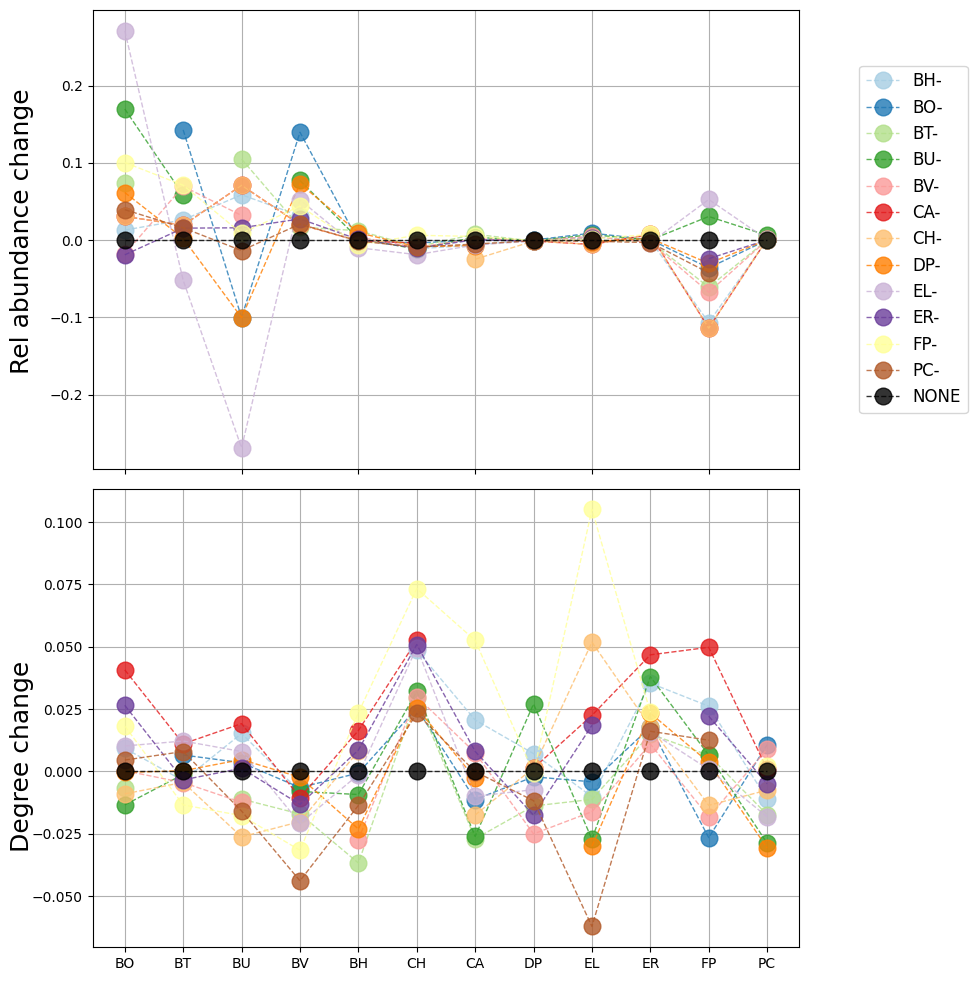

In [23]:
fig,ax = plt.subplots(2,figsize=(25,10))

abundances_exp_none = (abundances_exp.T-abundances_exp["NONE"]).T.drop("NONE",axis=1)

abundances_exp_none.plot(ax=ax[0],marker="o",figsize=(10,10),linestyle="--",linewidth=1,markersize=12,alpha=0.8,grid=True,cmap="Paired",legend=None)
(abundances_exp["NONE"]-abundances_exp["NONE"]).plot(ax=ax[0],color="black",marker="o",markersize=12,linestyle="--",linewidth=1,alpha=0.8,grid=True)
labels = ax[0].set_xticklabels("",rotation=90)
title1 = ax[0].set_title("Rel abundance change",x=-.1,y=0.2,fontsize=18,rotation=90)
ax[0].legend(loc='center right', bbox_to_anchor=(1.25, 0.5),fontsize=12)
ax[0].set_xlabel("")

centrality_sorted.loc[(~centrality_sorted.index.str.contains("NONE")),:].T.plot(ax=ax[1],marker="o",figsize=(10,10),linestyle="--",linewidth=1,markersize=12,alpha=0.8,grid=True,cmap="Paired",legend=None)
centrality_sorted.T["NONE"].plot(ax=ax[1],color="black",marker="o",markersize=12,linestyle="--",linewidth=1,alpha=0.8,grid=True)
names = centrality_sorted.columns.values
x = [name.split("_")[0][0].upper()+name.split("_")[1][0].upper() for name in names]

ax[1].set_xticks(np.arange(len(x)))
labels = ax[1].set_xticklabels(x)
title2 = ax[1].set_title("Degree change",x=-.1,y=0.2,fontsize=18,rotation=90)
plt.tight_layout()
#plt.savefig("figures_meeting/degree_centrality_mem.png",bbox_inches="tight")

### Degree centrality (frequency)

In [24]:

centrality_metrics_comm= {}

for comm in results_env.community.unique():
    print(comm)
    results_comm = results_env[results_env.community==comm].copy()
    
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=False,freq_cutoff=0.01)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=False,degree_type="both",max_iter=10000)
    
    centrality_metrics_comm[comm]=centrality_metrics
    

centrality = pd.concat(centrality_metrics_comm)["degree (data)"].unstack()
centrality =centrality.sort_index()


sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

centrality_sorted = centrality_sorted-centrality_sorted.T.loc[:,"NONE"].fillna(0)

PC-
FP-
BT-
CH-
EL-
DP-
BU-
ER-
CA-
BH-
BV-
NONE
BO-


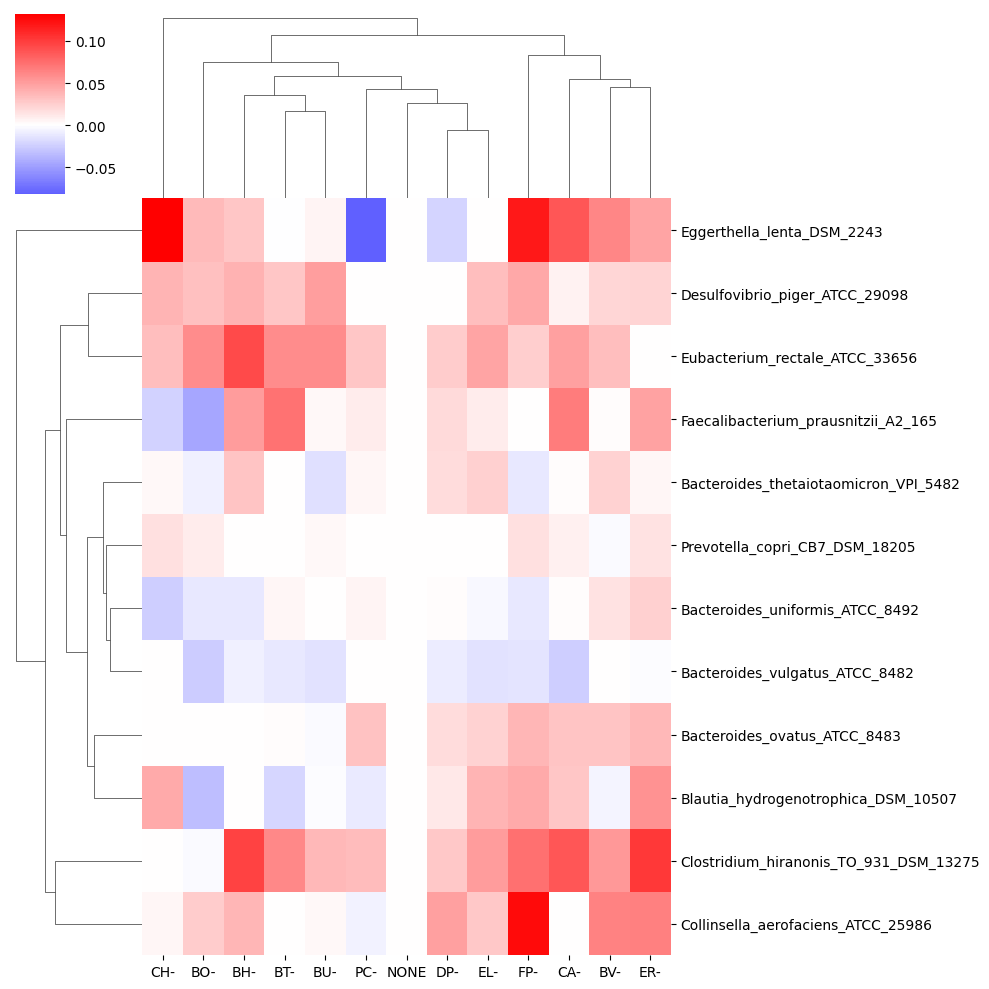

In [25]:

g = sns.clustermap(centrality_sorted.fillna(0).T,cmap="bwr",center=0)
#g.savefig("figures_meeting/clustermap_degree_gut.png", bbox_inches="tight")


### Closeness centrality (frequency)

In [26]:

centrality_metrics_comm= {}

for comm in results_env.community.unique():
    print(comm)
    results_comm = results_env[results_env.community==comm].copy()
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=False,freq_cutoff=0.01)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=True,degree_type="out")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

centrality = pd.concat(centrality_metrics_comm)["closeness (1/data)"].unstack()
centrality =centrality.sort_index()


sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

centrality_sorted = centrality_sorted-centrality_sorted.T.loc[:,"NONE"].fillna(0)

PC-
FP-
BT-
CH-
EL-
DP-
BU-
ER-
CA-
BH-
BV-
NONE
BO-


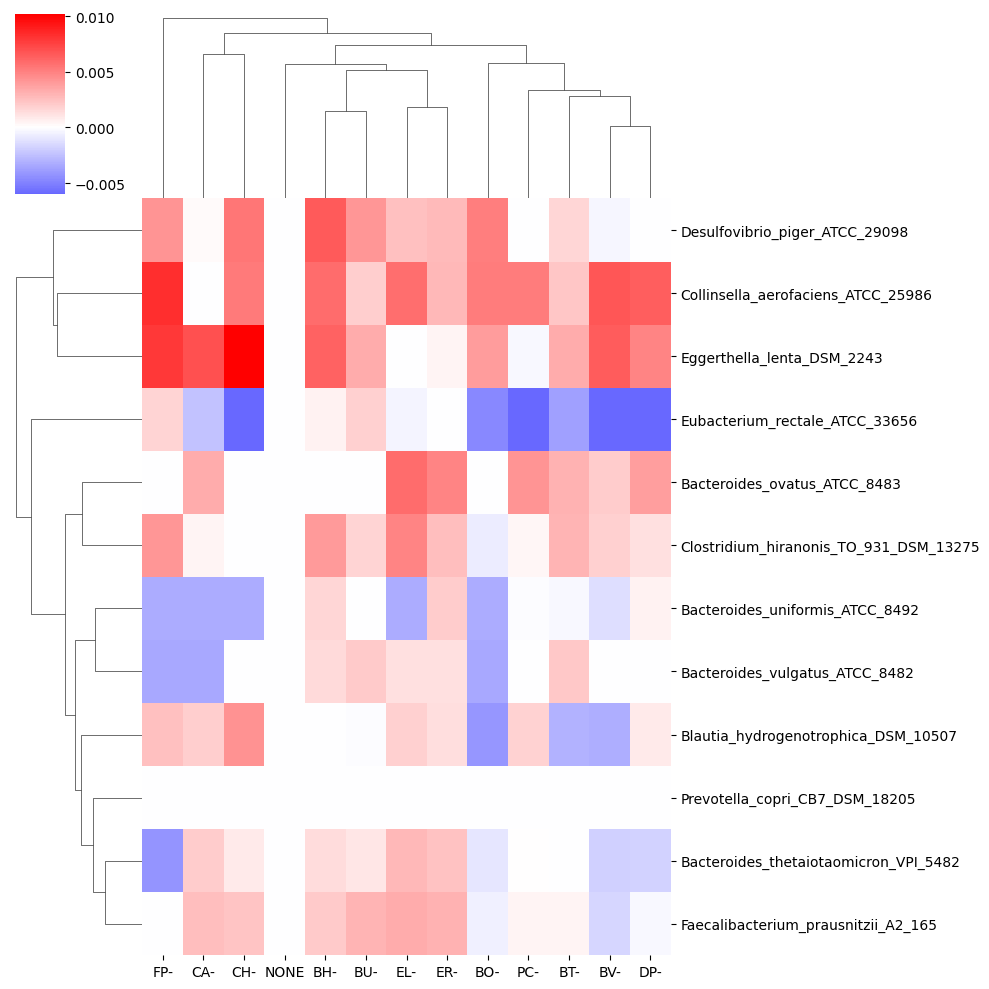

In [27]:

g = sns.clustermap(centrality_sorted.fillna(0).T,cmap="bwr",center=0)

#g.savefig("figures_meeting/clustermap_closeness_gut.png", bbox_inches="tight")


### Betweeness centrality (frequency)

In [28]:

centrality_metrics_comm= {}

for comm in results_env.community.unique():
    print(comm)
    results_comm = results_env[results_env.community==comm].copy()
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=False,freq_cutoff=0.01)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=True,degree_type="out")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

centrality = pd.concat(centrality_metrics_comm)["betweeness (1/data)"].unstack()
centrality =centrality.sort_index()


sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

centrality_sorted = centrality_sorted-centrality_sorted.T.loc[:,"NONE"].fillna(0)

PC-
FP-
BT-
CH-
EL-
DP-
BU-
ER-
CA-
BH-
BV-
NONE
BO-


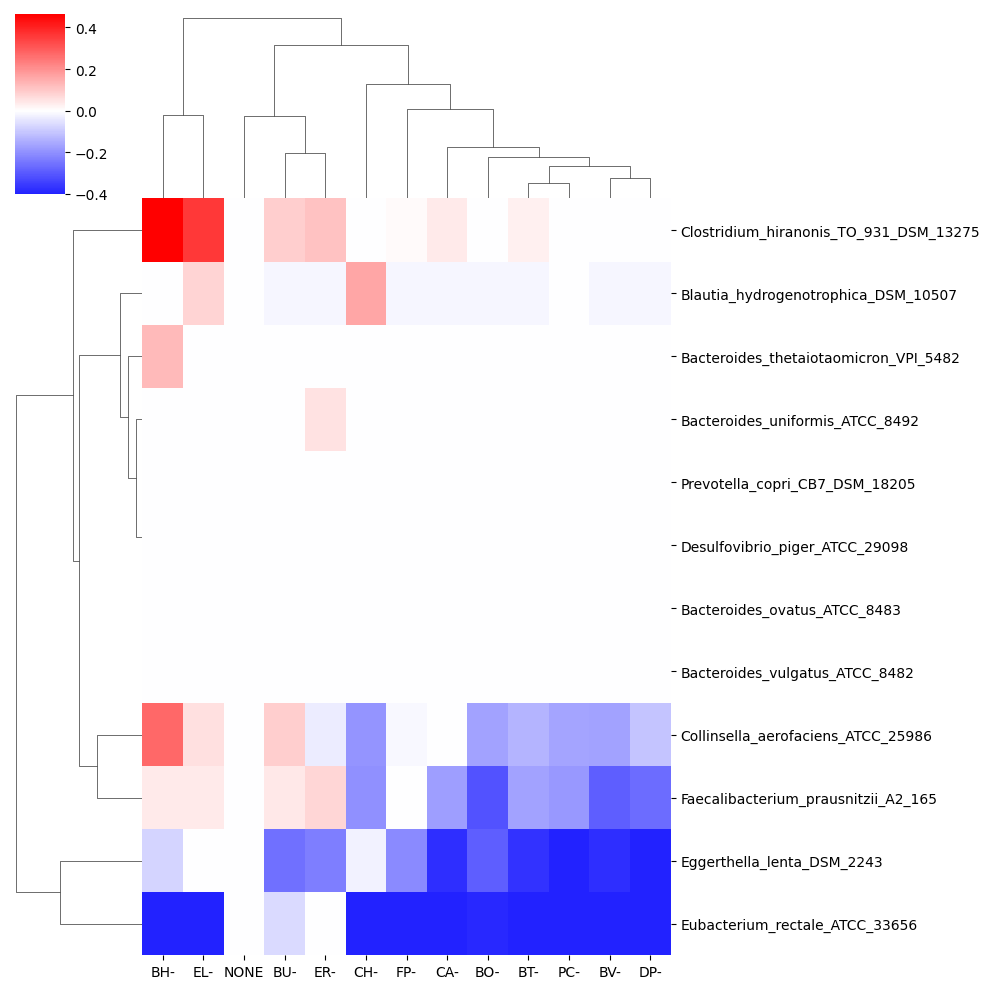

In [29]:
sns.clustermap(centrality_sorted.fillna(0).T,cmap="bwr",center=0)

In [30]:

don = results_env[["donor","compound","community","frequency"]].groupby(["donor","compound","community"]).mean()["frequency"].reset_index()
rec = results_env[["compound","receiver","community","frequency"]].groupby(["compound","receiver","community"]).mean()["frequency"].reset_index()

don.columns = ["A","B","community","frequency"]
rec.columns = ["A","B","community","frequency"]

don_rec_df = pd.concat([don,rec])
don_rec_df = don_rec_df.set_index(["community","A","B"])["frequency"]

In [31]:
import re

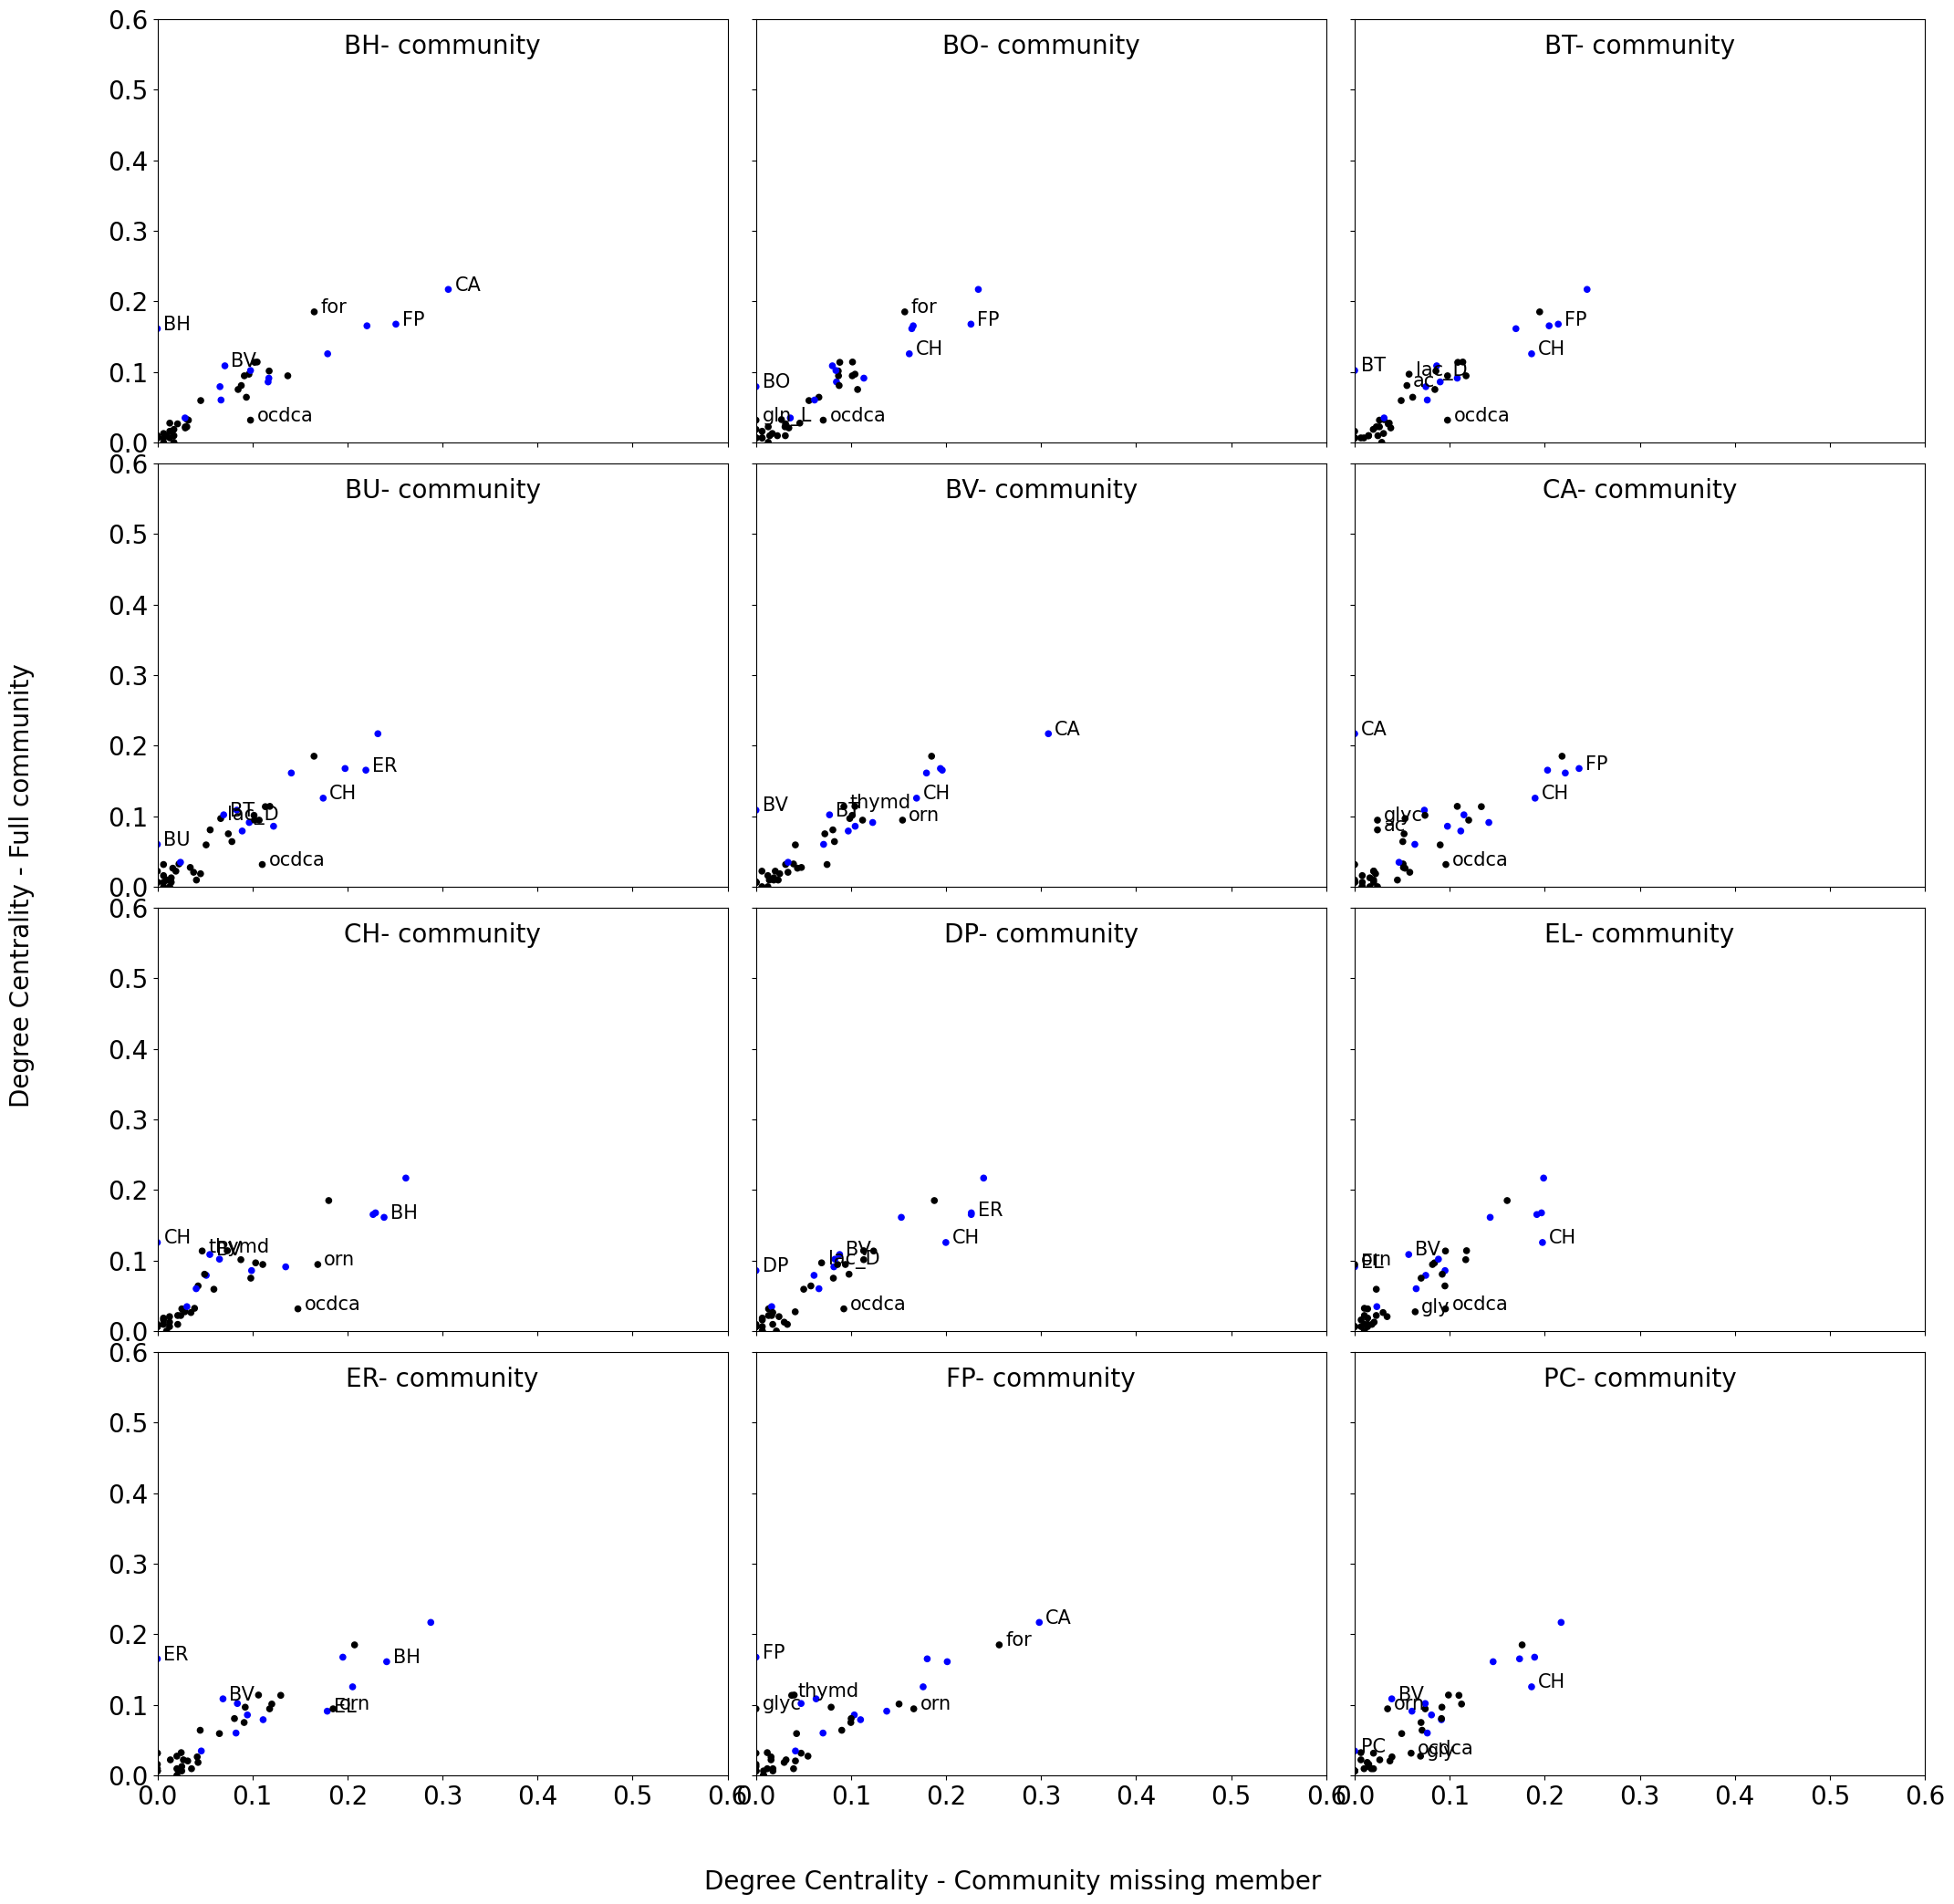

In [32]:
communities = [community_id for community_id in  results_env.community.sort_values().unique() if community_id!="NONE"]

metric = "degree (data)"
SP_centrality = False
fig,axs = plt.subplots(4,3,figsize=(25,25))
axs = axs.flatten()

bottom_row = ["ER-","FP-","PC-"]
left_col = ["BH-","BU-","CH-","ER-"]
ylim = 0.6

for i,community_id in enumerate(communities):
    ax = axs[i]
    
    NONE = networks.cooperation_centrality_metrics(don_rec_df.xs("NONE"),SP_centrality=SP_centrality)
    COMM = networks.cooperation_centrality_metrics(don_rec_df.xs(community_id),SP_centrality=SP_centrality)

    centrality_df = pd.concat([NONE[metric],COMM[metric]],axis=1)
    centrality_df.columns = ["NONE",community_id]
    centrality_df = centrality_df.fillna(0)

    centrality_df["is_met"] = centrality_df.index.str.startswith("M_")
    centrality_df.index = centrality_df.index.map(lambda x:re.sub(r"^M_(.*)__91__e__93__$", r"\1", x))
    centrality_df.index = centrality_df.index.map(lambda x:x if centrality_df.loc[x,"is_met"] else x.split("_")[0][0].upper()+x.split("_")[1][0].upper())
    
    colors = np.where(centrality_df["is_met"],'black','blue')


    centrality_df.plot(kind="scatter",y="NONE",x=community_id,ax = ax,c=colors)#,logy=True,logx=True)
    centrality_df["diff"] = centrality_df[community_id]-centrality_df["NONE"]

    lower, upper = centrality_df["diff"].quantile([0.05, 0.95])
    significant_nodes = centrality_df[(centrality_df["diff"] < lower) | (centrality_df["diff"] > upper)]

    for node, row in significant_nodes.iterrows():
        ax.annotate(node, (row[community_id], row["NONE"]), textcoords="offset points", xytext=(5,-1), ha='left',fontsize=15)
    
    
    ax.set_ylim([0,ylim])
    ax.set_xlim([0,ylim])
    

    if community_id not in bottom_row:
        ax.tick_params(labelbottom=False) 
    else:
        ax.tick_params(labelsize=20)
        #ax.set_yticklabels(ax.get_xticklabels(), rotation=90) 

    if community_id not in left_col:
        ax.tick_params(labelleft=False)

    else:    
        #plt.setp(ax.get_yticklabels()[-1], visible=False)
        ax.tick_params(labelsize=20)

    ax.set_xlabel("")
    ax.set_ylabel("")
    
    ax.set_title(community_id + " community", y=0.9,fontsize=20)
    
    #sns.despine(ax=ax, left=despine_left,bottom=False,right=True,top=True)
    
fig.text(0.5, 0.06, 'Degree Centrality - Community missing member', ha='center',fontsize=20)
fig.text(0.06, 0.5, 'Degree Centrality - Full community', va='center', rotation='vertical',fontsize=20)

plt.subplots_adjust(wspace=0.05, hspace=0.05)
#plt.savefig("figures_meeting/degree_centrality_met_mem.png",bbox_inches="tight")

### Plotting relative abundance

In [33]:
abundance = {}

for file in os.listdir("../output/Venturelli2018/results_steadiercom/results_growth_test/"):
    if file.endswith(".tsv") and file.endswith("_abundance.tsv"):
        abundance[file[:-4]] = pd.read_csv("../output/Venturelli2018/results_steadiercom/results_growth_test/"+file,sep="\t")

abundance_df = pd.concat(abundance)
abundance_df = abundance_df.reset_index(drop=True)

**Original results - many samples are dominated by one species**

In [34]:
abundance_df.set_index(["sample","community"]).index.unique().shape

(19500,)

Filter out the samples with dominating species

In [35]:
#abundance_df_reduced = abundance_df[(abundance_df.relative_abundance>0.0001)] #FILTERING!
abundance_df_reduced = abundance_df.copy()
#counts = abundance_df_reduced[["sample","community"]].value_counts()
#multiple_entries =counts[counts>1].index #Filtering...
#abundance_df_reduced = abundance_df_reduced.set_index(["sample","community"]).loc[multiple_entries].reset_index()

**Filtering cuts away most of the samples**

In [36]:
abundance_df_reduced.set_index(["sample","community"]).index.unique().shape

(19500,)

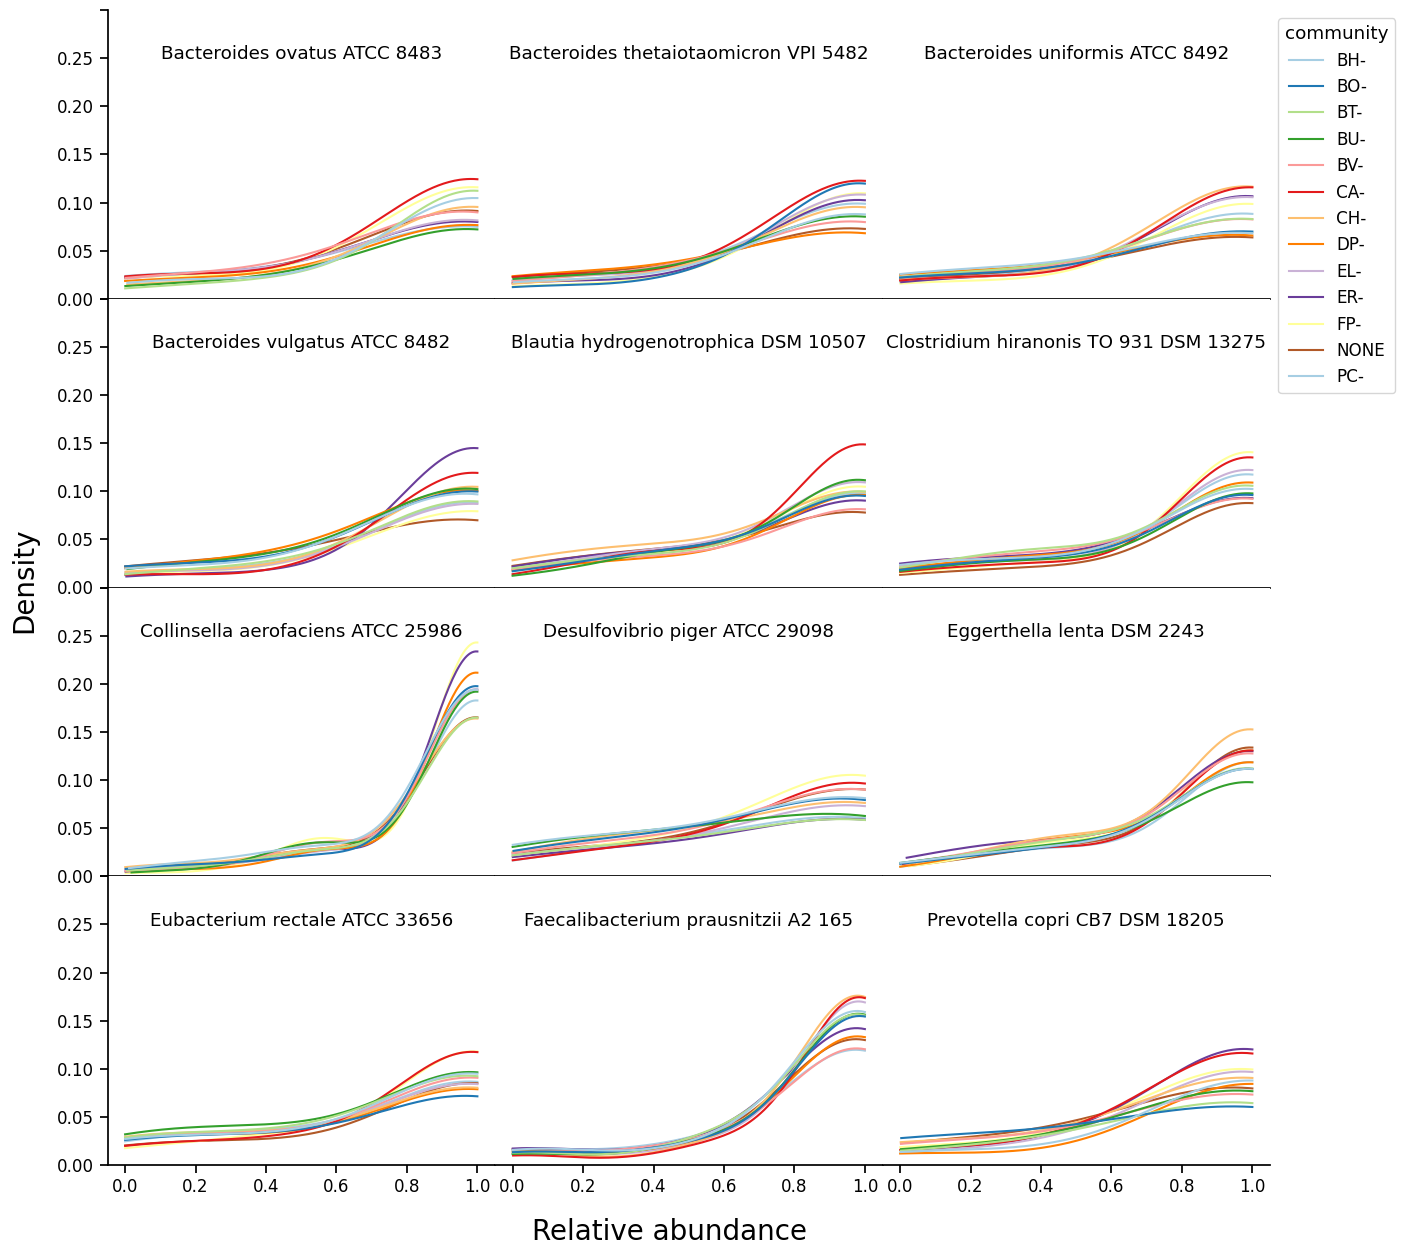

In [37]:
hue_order = abundance_df_reduced.community.sort_values().unique()
all_members = abundance_df_reduced.member.sort_values().unique()

bottom_row = ["Eubacterium_rectale_ATCC_33656","Faecalibacterium_prausnitzii_A2_165","Prevotella_copri_CB7_DSM_18205"]
left_col = ["Eubacterium_rectale_ATCC_33656","Bacteroides_ovatus_ATCC_8483","Bacteroides_vulgatus_ATCC_8482","Collinsella_aerofaciens_ATCC_25986"]

with sns.plotting_context(context='notebook', font_scale=1.1):
    fig,axs = plt.subplots(4,3,figsize=(15,15))
    axs = axs.flatten()
    for member,ax in zip(all_members,axs):
        if member=="Bacteroides_uniformis_ATCC_8492":
            legend=True
        else:
            legend=None
        abundance_df_spec = abundance_df_reduced[abundance_df_reduced.member==member].drop(["sample","member","medium"],axis=1).copy()
        ax = sns.kdeplot(abundance_df_spec,
                    x="relative_abundance",
                    hue="community",
                    ax=ax,
                    palette="Paired",
                    hue_order=hue_order,
                   #fill=True,
                   #alpha=,
                   cut=0,
                   legend=legend,
                   bw_adjust=2,
                    clip_on=True
                        )
        ax.set_title(" ".join(member.split("_")), y=0.8)
        
        ax.set_ylim([0,0.3])
        
        if member=="Bacteroides_uniformis_ATCC_8492":
            sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
            
        if member not in bottom_row:
            ax.tick_params(labelbottom=False) 
        else:
            plt.setp(ax.get_xticklabels()[0], visible=False)
            
        if member not in left_col:
            ax.set_yticks([])
            despine_left= True
        else:    
            plt.setp(ax.get_yticklabels()[-1], visible=False)
            despine_left= False 
        
        ax.set_xlabel("")
        ax.set_ylabel("")
        sns.despine(ax=ax, left=despine_left,bottom=False,right=True,top=True)
        
fig.text(0.5, 0.06, 'Relative abundance', ha='center',fontsize=20)
fig.text(0.06, 0.5, 'Density', va='center', rotation='vertical',fontsize=20)

plt.subplots_adjust(wspace=0, hspace=0.00)

#plt.savefig("figures_meeting/predicted_relative_abundances_all.png", bbox_inches="tight")


Text(0.5, 0, 'Relative abundance')

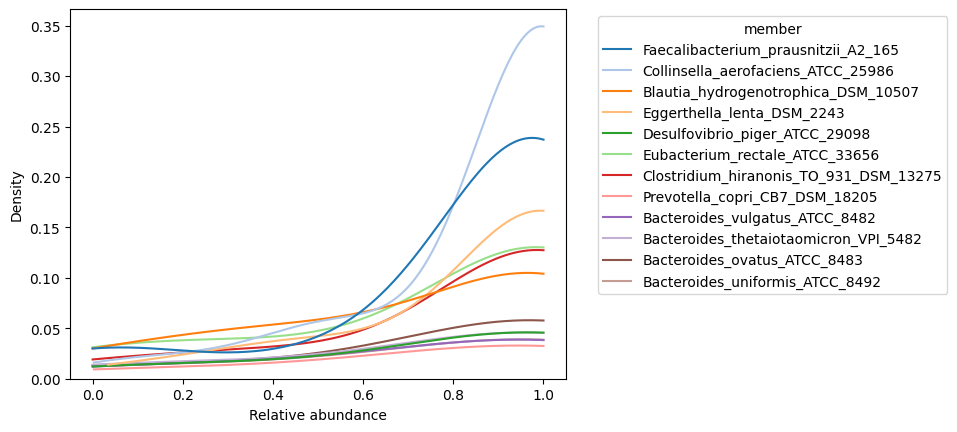

In [38]:
ax = sns.kdeplot(abundance_df_reduced[abundance_df_reduced.community=="NONE"],
            x="relative_abundance",
            hue="member",
           #fill=True,
           #alpha=0.2,
            cut=0,
            palette="tab20",
            bw_adjust=2,
           legend=True)

legend = ax.get_legend()
legend.set_bbox_to_anchor((1.05, 1))
legend.set_loc('upper left') 

ax.set_xlabel("Relative abundance")

#plt.savefig("figures_meeting/predicted_relative_abundances_NONE.png", bbox_inches="tight")